# 03 — Forecasting models and out-of-sample comparison

**Milestone M5.** Seven forecasting methods are compared on the 8 products, using four rolling 28-day test windows (forecast origins d_1800, d_1828, d_1856 and d_1885):

| Family | Model | How its form is chosen |
|---|---|---|
| Benchmarks | Naive, seasonal naive, 28-day moving average | Fixed rules |
| Exponential smoothing | ETS with additive error | AICc over {no trend, damped trend} × {no season, weekly season} |
| ARIMA | ARIMA(p,d,q) | AIC over p, q ∈ {0,1,2} within each allowed d |
| Seasonal ARIMA | SARIMA(p,d,q)(P,D,Q)₇ | AIC over p, q ∈ {0,1,2} and P, Q ∈ {0,1} within each allowed (d, D) |
| Intermittent demand | Croston with SBA bias correction | Smoothing α by in-sample MSE |

**How the pieces fit together:**
- Transform and d/D come from the M4 identification record **for the same origin**.
- AIC compares models only within one (d, D), because changing the differencing changes the data.
- When several (d, D) combinations are allowed, the **last 28 days of the training window** decide between them. The real test window is never used for any choice.
- All models are fitted on the 730 days before each origin, with Christmas closure days filled as described in notebook 02.

Code: `src/optichain/models_stat.py`, `src/optichain/backtest.py` (parallel and cached), `scripts/run_backtest.py`.

In [1]:
%matplotlib inline
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from optichain import plots as P
from optichain.config import PROJECT_ROOT, load_config
from optichain.data_pipeline import d_to_date, get_series

P.apply_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
cfg = load_config()
ITEMS, ORIGINS = cfg.series.items, cfg.forecast.origins
M = PROJECT_ROOT / "reports" / "metrics"
summary = pd.read_csv(M / "forecast_summary.csv")
metrics = pd.read_csv(M / "forecast_metrics.csv")
specs = pd.read_csv(M / "model_specs.csv")
cands = pd.read_csv(M / "aic_candidates.csv")
fc = pd.read_parquet(PROJECT_ROOT / "reports/forecasts/forecasts.parquet")
timing = pd.read_csv(M / "fit_timing.csv")
MODELS = ["naive", "snaive", "ma28", "ets", "arima", "sarima", "croston"]
print(f"{len(ITEMS)} items x {len(MODELS)} models x {len(ORIGINS)} origins = {len(ITEMS) * len(MODELS) * len(ORIGINS)} fits")

8 items x 7 models x 4 origins = 224 fits


## 1. Model selection inside each family

### Example: how SARIMA was chosen for FOODS_3_586 at d_1800

Identification (notebook 02) allowed d = 1 and D ∈ {0, 1}. For each D, the 36 (p, q, P, Q) orders were fitted on the training window minus its last 28 days. The best order by AIC within each D then forecast those 28 held-back days.

In [2]:
x = cands[(cands.item_id == "FOODS_3_586") & (cands.model == "sarima") & (cands.origin_d == 1800)]
print("Top 8 candidates by AIC (inner stage; AIC compared only within the same d, D):")
display(x.sort_values("aic").head(8)[["d", "D", "p", "q", "P", "Q", "aic", "bic", "converged"]])
row = specs[(specs.item_id == "FOODS_3_586") & (specs.model == "sarima") & (specs.origin_d == 1800)].iloc[0]
display(pd.DataFrame(json.loads(row["combo_scores"])))
print("Chosen:", row["spec"], "on", row["transform"], "scale")

Top 8 candidates by AIC (inner stage; AIC compared only within the same d, D):


,d,D,p,q,P,Q,aic,bic,converged
71,1.0,0.0,1.0,1.0,1.0,1.0,-105.278,-82.516,True
109,1.0,1.0,1.0,2.0,0.0,1.0,-104.957,-82.245,True
63,1.0,0.0,0.0,2.0,1.0,1.0,-104.736,-81.973,True
83,1.0,0.0,2.0,1.0,1.0,1.0,-104.424,-77.109,True
87,1.0,0.0,2.0,2.0,1.0,1.0,-104.135,-72.267,True
105,1.0,1.0,1.0,1.0,0.0,1.0,-103.573,-85.403,True
97,1.0,1.0,0.0,2.0,0.0,1.0,-103.161,-84.991,True
111,1.0,1.0,1.0,2.0,1.0,1.0,-103.035,-75.781,True


,d,D,order,inner_rmse
0,1,0,"[1, 1, 1, 1]",9.852
1,1,1,"[1, 2, 0, 1]",9.956


Chosen: ARIMA(1,1,1)(1,0,1)[7] on log1p scale


- Within D = 0 the AIC winner is (1,1,1)(1,0,1)₇, and within D = 1 it is (1,1,2)(0,1,1)₇.
- On the 28 held-back days, the D = 0 model was slightly more accurate (RMSE 9.85 vs 9.96), so seasonal differencing was **not** used at this origin. At d_1885 the two were nearly tied, and D = 1 won by a hair.
- This matches the M4 finding: the weekly pattern is real, but a seasonal AR term with coefficient near 1 captures it about as well as differencing does.
- AIC values are listed only to rank orders **within** one (d, D). Comparing AIC across different D would be invalid, because the differenced data differ.
- Convergence: only 0.5% of all candidate fits failed to converge, and those were excluded.

### Chosen specifications at every origin

In [3]:
for m in ["ets", "arima", "sarima"]:
    print(m.upper())
    display(specs[specs.model == m].pivot(index="item_id", columns="origin_d", values="spec").loc[ITEMS])

ETS


origin_d,1800,1828,1856,1885
item_id,,,,
FOODS_3_586,"ETS(A,N,A)","ETS(A,N,A)","ETS(A,N,A)","ETS(A,N,A)"
HOUSEHOLD_1_447,"ETS(A,N,A)","ETS(A,N,A)","ETS(A,N,A)","ETS(A,N,A)"
FOODS_3_203,"ETS(A,N,A)","ETS(A,N,A)","ETS(A,N,A)","ETS(A,N,A)"
HOBBIES_1_189,"ETS(A,N,N)","ETS(A,N,N)","ETS(A,N,N)","ETS(A,N,N)"
HOBBIES_1_030,"ETS(A,N,A)","ETS(A,N,A)","ETS(A,N,A)","ETS(A,N,A)"
HOUSEHOLD_1_469,"ETS(A,Ad,A)","ETS(A,N,A)","ETS(A,N,A)","ETS(A,N,A)"
FOODS_3_242,"ETS(A,Ad,A)","ETS(A,N,A)","ETS(A,N,A)","ETS(A,N,A)"
HOUSEHOLD_1_046,"ETS(A,N,A)","ETS(A,N,A)","ETS(A,N,A)","ETS(A,N,A)"


ARIMA


origin_d,1800,1828,1856,1885
item_id,,,,
FOODS_3_586,"ARIMA(2,1,2)","ARIMA(2,1,2)","ARIMA(2,1,2)","ARIMA(2,1,2)"
HOUSEHOLD_1_447,"ARIMA(1,1,1)","ARIMA(2,1,1)","ARIMA(2,1,1)","ARIMA(1,1,1)"
FOODS_3_203,"ARIMA(2,0,1)","ARIMA(2,0,2)","ARIMA(2,0,1)","ARIMA(1,0,2)"
HOBBIES_1_189,"ARIMA(0,1,1)","ARIMA(1,0,2)","ARIMA(1,0,2)","ARIMA(1,0,2)"
HOBBIES_1_030,"ARIMA(0,1,1)","ARIMA(0,1,1)","ARIMA(0,1,1)","ARIMA(2,0,2)"
HOUSEHOLD_1_469,"ARIMA(2,1,1)","ARIMA(2,1,1)","ARIMA(2,1,1)","ARIMA(0,1,1)"
FOODS_3_242,"ARIMA(0,0,1)","ARIMA(0,0,0)","ARIMA(0,0,0)","ARIMA(2,0,2)"
HOUSEHOLD_1_046,"ARIMA(2,0,2)","ARIMA(1,0,1)","ARIMA(1,0,1)","ARIMA(0,0,1)"


SARIMA


origin_d,1800,1828,1856,1885
item_id,,,,
FOODS_3_586,"ARIMA(1,1,1)(1,0,1)[7]","ARIMA(1,1,1)(1,0,1)[7]","ARIMA(1,1,1)(1,0,1)[7]","ARIMA(1,1,1)(0,1,1)[7]"
HOUSEHOLD_1_447,"ARIMA(2,1,1)(1,0,1)[7]","ARIMA(2,1,1)(1,0,1)[7]","ARIMA(2,1,1)(1,0,1)[7]","ARIMA(2,1,1)(1,0,1)[7]"
FOODS_3_203,"ARIMA(1,0,1)(1,0,1)[7]","ARIMA(1,0,1)(1,0,1)[7]","ARIMA(1,0,1)(1,0,1)[7]","ARIMA(1,0,1)(1,0,1)[7]"
HOBBIES_1_189,"ARIMA(0,1,1)(0,0,0)[7]","ARIMA(1,0,2)(0,0,0)[7]","ARIMA(1,0,2)(0,0,0)[7]","ARIMA(1,0,2)(0,0,0)[7]"
HOBBIES_1_030,"ARIMA(0,1,1)(1,0,1)[7]","ARIMA(0,1,1)(1,0,1)[7]","ARIMA(0,1,1)(1,0,1)[7]","ARIMA(2,0,2)(1,0,1)[7]"
HOUSEHOLD_1_469,"ARIMA(2,1,1)(1,0,1)[7]","ARIMA(2,1,1)(1,0,1)[7]","ARIMA(2,1,1)(1,0,1)[7]","ARIMA(0,1,1)(1,0,1)[7]"
FOODS_3_242,"ARIMA(0,0,1)(1,0,1)[7]","ARIMA(0,0,0)(1,0,1)[7]","ARIMA(0,0,0)(1,0,1)[7]","ARIMA(0,0,0)(1,0,1)[7]"
HOUSEHOLD_1_046,"ARIMA(2,0,2)(0,0,0)[7]","ARIMA(0,0,1)(1,0,1)[7]","ARIMA(0,0,1)(1,0,1)[7]","ARIMA(0,0,1)(1,0,1)[7]"


**Observations**

- **ETS** picks an additive weekly seasonal form ETS(A,N,A) for 7 of 8 products. HOBBIES_1_189 is the exception and gets no seasonality, consistent with its flat weekday profile in notebook 01. A damped trend is chosen only twice, both at the first origin.
- **SARIMA** almost always includes seasonal AR and MA terms (1,0,1)₇. The weekly pattern goes into these terms, not into seasonal differencing, as M4 predicted.
- **Conflict items** (HOUSEHOLD_1_447, HOUSEHOLD_1_469, HOBBIES_1_030) often end up with d = 1 after the inner holdout: a drifting level is forecast better by a model that does not pull back to a fixed mean.
- **White-noise items:** FOODS_3_242 gets ARIMA(0,0,0), which is just a constant mean, at two of four origins, exactly as the M4 Ljung–Box result suggested.
- **Orders are fairly stable across origins**, which is reassuring for a model meant to be reused.

## 2. Out-of-sample accuracy

Mean RMSSE over the four 28-day test windows (lower is better; below 1 beats an in-sample one-step naive forecast).

In [4]:
piv = summary.pivot(index="item_id", columns="model", values="rmsse").loc[ITEMS, MODELS]
display(piv.style.format("{:.3f}").highlight_min(axis=1, props="font-weight:bold;background-color:#cde2fb"))
rank = piv.rank(axis=1)
overall = pd.DataFrame({"mean RMSSE": piv.mean(), "mean rank (1 = best)": rank.mean(),
                        "times best": (rank == 1).sum()}).sort_values("mean rank (1 = best)")
display(overall)

model,naive,snaive,ma28,ets,arima,sarima,croston
item_id,,,,,,,
FOODS_3_586,1.066,0.664,0.736,0.580,0.700,0.610,0.700
HOUSEHOLD_1_447,1.032,1.194,0.933,0.864,0.922,0.886,0.920
FOODS_3_203,1.171,1.107,0.812,0.775,0.837,0.787,0.806
HOBBIES_1_189,1.000,1.187,0.834,0.820,0.827,0.827,0.829
HOBBIES_1_030,1.662,1.360,1.077,1.035,1.076,1.047,1.074
HOUSEHOLD_1_469,0.540,0.448,0.418,0.428,0.409,0.408,0.420
FOODS_3_242,1.157,1.092,0.951,0.887,0.928,0.878,0.948
HOUSEHOLD_1_046,0.865,1.042,0.810,0.791,0.796,0.793,0.803


,mean RMSSE,mean rank (1 = best),times best
model,,,
ets,0.773,1.625,6
sarima,0.779,1.812,2
arima,0.812,3.562,0
croston,0.812,3.625,0
ma28,0.821,4.750,0
snaive,1.012,6.000,0
naive,1.062,6.625,0


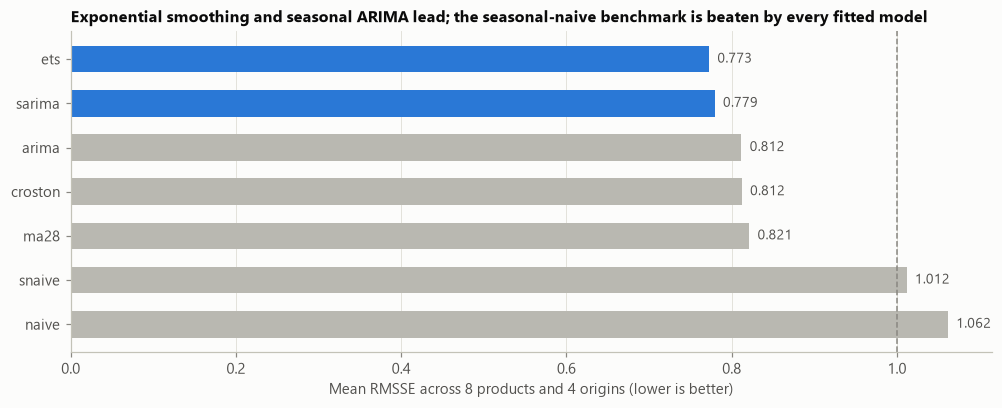

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.6))
order = overall.index[::-1]
colors = [P.BLUE if m in ("ets", "sarima") else P.CONTEXT for m in order]
ax.barh(order, overall.loc[order, "mean RMSSE"], color=colors, height=0.6)
for i, m in enumerate(order):
    ax.text(overall.loc[m, "mean RMSSE"] + 0.01, i, f"{overall.loc[m, 'mean RMSSE']:.3f}", va="center", fontsize=9, color=P.INK_2)
ax.axvline(1, color=P.MUTED, ls="--", lw=1)
ax.set_xlabel("Mean RMSSE across 8 products and 4 origins (lower is better)")
ax.set_title("Exponential smoothing and seasonal ARIMA lead; the seasonal-naive benchmark is beaten by every fitted model")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
plt.show()

**Findings**

- **ETS is the most accurate method overall** (mean RMSSE 0.773, best on 6 of 8 products). **SARIMA is a close second** (0.779) and best on the remaining 2: HOUSEHOLD_1_469 and FOODS_3_242.
- **Every fitted model beats both naive benchmarks.** Against seasonal naive, ETS and SARIMA are about 21% more accurate on average (the `skill_vs_snaive` column).
- **The margins between the fitted models are small.** ETS vs SARIMA differ by under 1% on average, and the 28-day average is only about 6% behind ETS. With four test windows per product, differences of a few percent are within normal fold-to-fold variation. ETS and SARIMA should be treated as *jointly* best, rather than reading too much into their order.
- **Where the gain is largest:** FOODS_3_586 (steady, strongly weekly) improves from 0.664 (seasonal naive) to 0.580 (ETS). That is the series type where structured models are expected to pay off.
- **Where models add little:** on the white-noise items (FOODS_3_242, HOUSEHOLD_1_046), all fitted models land within about 0.1 of the moving average, as notebook 02 predicted.
- **AIC cannot choose between families.** ETS is fitted on the original scale and SARIMA on log1p or differenced data, so their likelihoods, and hence their AICs, are not comparable. AIC is used only to pick orders *within* a family; families are compared on held-out data.

## 3. Bias and prediction-interval calibration

In [6]:
cal = summary.groupby("model")[["mae", "bias", "cov80", "cov95"]].mean().loc[MODELS]
cal.columns = ["MAE (units/day)", "bias (forecast - actual)", "80% interval coverage", "95% interval coverage"]
display(cal.style.format("{:.3f}"))

,MAE (units/day),bias (forecast - actual),80% interval coverage,95% interval coverage
model,,,,
naive,5.420,1.951,0.987,0.996
snaive,4.406,-0.170,0.903,0.980
ma28,3.894,0.161,0.820,0.935
ets,3.533,0.178,0.838,0.936
arima,3.770,-0.225,0.824,0.926
sarima,3.584,-0.118,0.818,0.924
croston,3.787,-0.139,0.827,0.932


- **Intervals are well calibrated for the fitted models.** The 80% intervals contain the actual value 82–84% of the time, and the 95% intervals 92–94%. This matters downstream: the inventory safety stock is sized from the same error estimates.
- **The naive methods over-cover** (naive 99%): their intervals are honest but very wide, which would translate into excess safety stock.
- **Bias is small for every fitted model**, at most ±0.25 units/day on average. ETS and the moving average lean slightly high and ARIMA slightly low. Naive's +1.95 bias comes from carrying forward a single high day.

## 4. What the forecasts look like

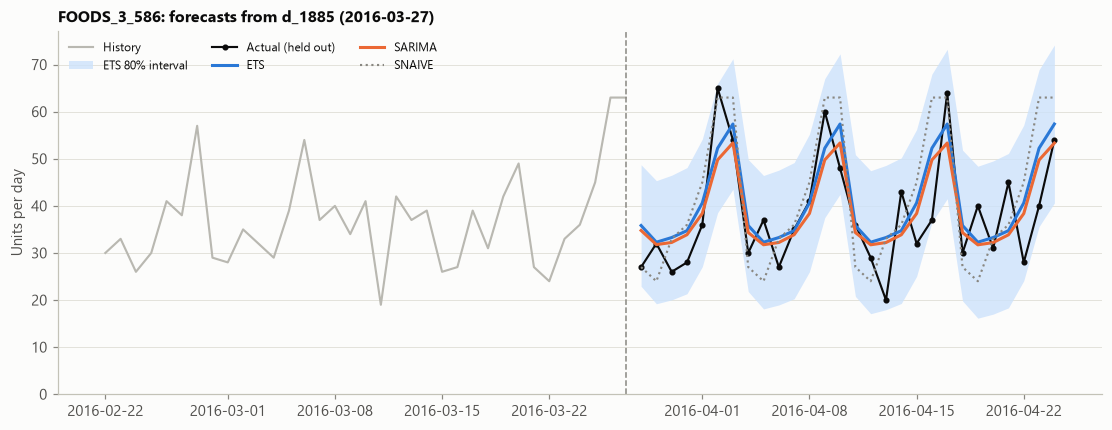

In [7]:
item, origin = "FOODS_3_586", 1885
y = get_series(pd.read_parquet(cfg.data.processed_dir / "selected_series.parquet"), item, cfg.data.max_day)
fig, ax = plt.subplots(figsize=(10, 3.8))
hist = y.loc[d_to_date(origin - 34):d_to_date(origin)]
ax.plot(hist.index, hist.values, color=P.CONTEXT, lw=1.4, label="History")
f = fc[(fc.item_id == item) & (fc.origin_d == origin) & (fc.h <= 28)]
ets = f[f.model == "ets"]
ax.fill_between(pd.to_datetime(ets["date"]), ets["lo80"], ets["hi80"], color=P.SEQ_BLUE[0], alpha=0.8, lw=0, label="ETS 80% interval")
ax.plot(pd.to_datetime(ets["date"]), ets["y_true"], color=P.INK, lw=1.4, marker="o", ms=3, label="Actual (held out)")
for m, c, ls in [("ets", P.BLUE, "-"), ("sarima", P.SERIES[1], "-"), ("snaive", P.MUTED, ":")]:
    g = f[f.model == m]
    ax.plot(pd.to_datetime(g["date"]), g["yhat"], color=c, lw=2 if m != "snaive" else 1.4, ls=ls, label=m.upper())
ax.axvline(d_to_date(origin), color=P.MUTED, ls="--", lw=1)
ax.set_title(f"{item}: forecasts from d_{origin} ({d_to_date(origin).date()})")
ax.set_ylabel("Units per day"); ax.set_ylim(bottom=0)
ax.legend(ncols=3, loc="upper left", fontsize=8)
plt.show()

- ETS and SARIMA both reproduce the weekend peaks, but at a **smoothed** amplitude. They average the weekly shape over many weeks instead of copying one noisy week, as seasonal naive does.
- The actual series stays mostly inside the 80% band. The misses are the sharp peaks, which no model of the daily mean can predict exactly.

## 5. Effect on the inventory simulation

The forecast-driven policy (P1) picks its model at each origin from the folds **already completed** by that origin. It therefore starts with seasonal naive and switches to ETS, SARIMA or ARIMA once evidence accumulates.

In [8]:
pm = pd.read_csv(PROJECT_ROOT / "reports/inventory/policy_metrics.csv")
choice = pd.read_csv(PROJECT_ROOT / "reports/inventory/model_choice.csv")
display(choice.pivot(index="item_id", columns="origin_d", values="model").loc[ITEMS])
cmp = pm.pivot(index="item_id", columns="policy", values="total_cost")[["P0 baseline", "P1 forecast", "Perfect foresight"]].loc[ITEMS]
cmp["P1 vs P0"] = cmp["P1 forecast"] / cmp["P0 baseline"] - 1
display(cmp.style.format({"P0 baseline": "${:.2f}", "P1 forecast": "${:.2f}", "Perfect foresight": "${:.2f}", "P1 vs P0": "{:+.0%}"}))
tot = pm.groupby("policy")[["total_cost", "lost_units"]].sum().loc[["P0 baseline", "P1 forecast"]]
display(tot)

origin_d,1800,1828,1856,1885
item_id,,,,
FOODS_3_586,snaive,snaive,ets,ets
HOUSEHOLD_1_447,snaive,ets,ets,ets
FOODS_3_203,snaive,ets,ets,ets
HOBBIES_1_189,snaive,ets,arima,arima
HOBBIES_1_030,snaive,ets,ets,ets
HOUSEHOLD_1_469,snaive,ma28,croston,sarima
FOODS_3_242,snaive,sarima,sarima,sarima
HOUSEHOLD_1_046,snaive,ets,ets,ets


policy,P0 baseline,P1 forecast,Perfect foresight,P1 vs P0
item_id,,,,
FOODS_3_586,$115.25,$90.89,$92.94,-21%
HOUSEHOLD_1_447,$74.75,$68.67,$77.67,-8%
FOODS_3_203,$81.89,$77.69,$80.28,-5%
HOBBIES_1_189,$70.41,$69.07,$76.37,-2%
HOBBIES_1_030,$62.93,$66.95,$81.32,+6%
HOUSEHOLD_1_469,$98.21,$88.64,$27.12,-10%
FOODS_3_242,$100.19,$80.20,$73.39,-20%
HOUSEHOLD_1_046,$70.25,$58.06,$86.38,-17%


,total_cost,lost_units
policy,,
P0 baseline,673.868,49.0
P1 forecast,600.150,44.0


- With the statistical models available, the forecast-driven plan is **cheaper than the simple rule on 7 of 8 products**: $600 vs $674 in total (−11%), and it misses fewer sales (44 vs 49 units).
- The exception is **HOBBIES_1_030**, the spikiest product. Its large, unpredictable spikes make any forecast-based safety stock either too small (missed sales) or costly.
- These are simulation results under **hypothetical** costs and lead times (see `config.yaml`). M7 will test how sensitive they are to those assumptions.

## 6. Practical notes and limitations

- **Compute.** The backtest ran 2,342 candidate fits in total, 1,800 of them for SARIMA. A SARIMA search averages ~80 s per (product, origin). With 11 parallel workers the full backtest takes ~4 minutes, and fits are cached, so re-runs are instant unless data, settings or identification change.
- **Four folds is a small sample.** The method ranking is stable at the top (ETS and SARIMA), but the exact order among close competitors may change on new data. The untouched final test window (d_1914–d_1941) will be used once, in M9.
- **Back-transformation.** For log1p models, `expm1` of the mean forecast gives roughly the *median* on the original scale, which runs slightly low for right-skewed demand. This affects only FOODS_3_586 and FOODS_3_203. The small negative SARIMA bias is consistent with it.
- **Next (M6):** residual diagnostics (Ljung–Box, residual ACF, QQ plots) for the selected model on each product, and the ARCH-LM test that decides whether GARCH is justified.